# HW-2. Data Diet: EL2N и 3 независимых повтора

Проверяем, помогает ли EL2N выбрать полезную половину CIFAR-10.
Сравниваем небольшую CNN на всех данных, случайных 50% и 50% с наибольшим EL2N.
Все итоговые модели обучаются **с нуля, одинаковое число шагов**.

Три независимых повтора: в каждом своя начальная модель для EL2N, случайная
подвыборка и начальные веса итоговых моделей. Внутри повтора у 3х итоговых
моделей одинаковые начальные веса. Всего 3 начальных + 9 итоговых обучений.

Это частичное воспроизведение: небольшая CNN вместо ResNet18, короткое обучение,
одна модель для EL2N в каждом повторе вместо усреднения оценок по ансамблю.
GraNd и Forget Score не проверяются. Три повтора позволяют оценить разброс,
но сами по себе не доказывают статистическую значимость.

**Colab:** включите GPU (T4, A100 подходит), выполняйте ячейки по порядку.
Дополнительные `.py` не нужны. Google Drive хранит результаты и контрольные точки.
После отключения повторите ячейки с теми же настройками — обучение продолжится.

Источник: [Deep Learning on a Data Diet, исправленная версия](https://arxiv.org/abs/2107.07075v2).


In [1]:
import hashlib
import json
import math
import platform
import random
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

if not torch.cuda.is_available():
    raise RuntimeError(
        "В Colab включите GPU: Среда выполнения → Сменить среду выполнения."
    )

DEVICE = torch.device("cuda")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)


GPU: Tesla T4
PyTorch: 2.11.0+cu130


## 1. Настройки

В каждом повторе начальная модель обучается 5 эпох на всем train, затем вычисляется
EL2N. Каждая итоговая модель делает 8 000 шагов: примерно 20,5 прохода по полному
набору или 40,8 по половине. Это существенно меньше бюджета статьи.

Три набора seed заданы заранее. После замера времени можно изменить `train_steps`,
**до основных запусков**, одинаково для всех вариантов. Не выбираем настройки,
seed или лучший повтор по тестовой точности. Сохраняем результаты всех повторов


In [2]:
USE_DRIVE = True
CONFIG = {
    "version": 2,
    "model": "small_cnn_32_64_128_gap",
    "batch_size": 128,
    "score_batch_size": 512,
    "score_epochs": 5,
    "train_steps": 8000,
    "keep_fraction": 0.5,
    "lr": 0.05,
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "seeds": [
        {"score": 11, "train": 22, "subset": 33},
        {"score": 111, "train": 122, "subset": 133},
        {"score": 211, "train": 222, "subset": 233},
    ],
    "num_workers": 2,
}

if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/hw2_data_diet")
else:
    ROOT = Path("/content/hw2_data_diet")

assert CONFIG["train_steps"] > 0 and CONFIG["score_epochs"] > 0
assert 0 < CONFIG["keep_fraction"] < 1
assert len(CONFIG["seeds"]) >= 2
all_seeds = [seed for seeds in CONFIG["seeds"] for seed in seeds.values()]
assert len(set(all_seeds)) == len(all_seeds)
RUN_ID = hashlib.sha256(
    json.dumps(CONFIG, sort_keys=True).encode()
).hexdigest()[:12]
RUN_DIR = ROOT / RUN_ID
RESULTS = RUN_DIR / "results"
CHECKPOINTS = RUN_DIR / "checkpoints"
RESULTS.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)
(RESULTS / "config.json").write_text(json.dumps(CONFIG, indent=2))
environment = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
}
(RESULTS / "environment.json").write_text(json.dumps(environment, indent=2))
print("Папка запуска:", RUN_DIR)


Mounted at /content/drive
Папка запуска: /content/drive/MyDrive/hw2_data_diet/4ad4ed70df4f


## 2. Данные и модель

Данные скачиваются на локальный диск Colab. Для обучения используются случайный
crop и отражение, для оценки EL2N и теста - только нормализация

CNN: три блока из двух сверток с BatchNorm/ReLU и MaxPool,
затем GlobalAvgPool и Linear на 10 классов


In [3]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
train_data = datasets.CIFAR10(
    "/content/data", train=True, download=True, transform=train_transform
)
score_data = datasets.CIFAR10(
    "/content/data", train=True, transform=eval_transform
)
test_data = datasets.CIFAR10(
    "/content/data", train=False, transform=eval_transform
)
assert train_data.targets == score_data.targets


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_loader(data, batch_size, shuffle=False, seed=0):
    return DataLoader(
        data,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=CONFIG["num_workers"],
        pin_memory=True,
        generator=torch.Generator().manual_seed(seed),
    )


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_channels = 3
        for channels in (32, 64, 128):
            for _ in range(2):
                layers.extend([
                    nn.Conv2d(in_channels, channels, 3, padding=1, bias=False),
                    nn.BatchNorm2d(channels),
                    nn.ReLU(inplace=True),
                ])
                in_channels = channels
            layers.append(nn.MaxPool2d(2))
        layers.append(nn.AdaptiveAvgPool2d(1))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(128, 10)

    def forward(self, images):
        return self.classifier(self.features(images).flatten(1))


print("Train:", len(train_data), "Test:", len(test_data))
print("Параметры CNN:", sum(p.numel() for p in SmallCNN().parameters()))


100%|██████████| 170M/170M [33:25<00:00, 85.0kB/s]


Train: 50000 Test: 10000
Параметры CNN: 288746


## 3. Обучение и сохранение

Для итоговых моделей используется SGD с одинаковым cosine-расписанием learning rate
по шагам. У начальной модели learning rate постоянный. Модели обучаются в FP32.
Контрольная точка сохраняется после каждого прохода по выбранным данным.
Одинаковый seed дает итоговым моделям одинаковые начальные веса.


In [4]:
def train_batch(model, images, labels, optimizer):
    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    loss = nn.functional.cross_entropy(model(images), labels)
    if not torch.isfinite(loss):
        raise RuntimeError("Loss стал NaN/Inf; остановка обучения.")
    loss.backward()
    optimizer.step()
    return loss.item()


def train_model(name, indices, steps, seed, decay=True):
    seed_all(seed)
    model = SmallCNN().to(DEVICE)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=CONFIG["lr"], momentum=CONFIG["momentum"],
        weight_decay=CONFIG["weight_decay"], nesterov=True,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=steps
    ) if decay else None
    checkpoint = CHECKPOINTS / f"{name}.pt"
    subset = Subset(train_data, indices.tolist())
    signature = {
        "indices": hashlib.sha256(indices.tobytes()).hexdigest(),
        "steps": steps, "seed": seed, "decay": decay,
    }
    step, epoch, seconds = 0, 0, 0.0
    history = []
    if checkpoint.exists():
        state = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
        if state["signature"] != signature:
            raise ValueError("Настройки не совпадают с контрольной точкой.")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        if scheduler is not None:
            scheduler.load_state_dict(state["scheduler"])
        step, epoch, seconds = state["step"], state["epoch"], state["seconds"]
        history = state["history"]
        del state
        print(f"{name}: сохранено {step}/{steps} шагов")

    while step < steps:
        seed_all(seed + epoch)
        loader = make_loader(
            subset, CONFIG["batch_size"], shuffle=True, seed=seed + epoch
        )
        model.train()
        started = time.perf_counter()
        losses = []
        for images, labels in loader:
            losses.append(train_batch(model, images, labels, optimizer))
            if scheduler is not None:
                scheduler.step()
            step += 1
            if step == steps:
                break
        seconds += time.perf_counter() - started
        epoch += 1
        history.append({
            "step": step, "epoch": epoch, "loss": float(np.mean(losses)),
            "train_seconds": seconds,
        })
        state = {
            "signature": signature, "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict() if scheduler else None,
            "step": step, "epoch": epoch, "seconds": seconds,
            "history": history,
        }
        temporary = checkpoint.with_suffix(".tmp")
        torch.save(state, temporary)
        temporary.replace(checkpoint)
        print(f"{name}: {step}/{steps}, loss={history[-1]['loss']:.3f}")

    pd.DataFrame(history).to_csv(RESULTS / f"{name}_history.csv", index=False)
    return model, seconds


@torch.inference_mode()
def test_accuracy(model):
    model.eval()
    correct, total = 0, 0
    for images, labels in make_loader(test_data, CONFIG["score_batch_size"]):
        predictions = model(images.to(DEVICE)).argmax(1).cpu()
        correct += (predictions == labels).sum().item()
        total += len(labels)
    return correct / total


## 4. Короткий замер времени

20 шагов прогрева и 100 измеряемых шагов. Пробная модель затем удаляется.
Оценка приблизительная: она не включает вычисление EL2N, тестирование, сохранение
и возможные замедления Colab. Если она превышает бюджет, уменьшите `train_steps`
в разделе 1 и повторите ячейки начиная с настроек. Затем зафиксируйте конфигурацию.


In [5]:
def benchmark():
    seed_all(999)
    model = SmallCNN().to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=CONFIG["lr"], momentum=0.9)
    loader = make_loader(train_data, CONFIG["batch_size"], shuffle=True, seed=999)
    torch.cuda.reset_peak_memory_stats()
    started = None
    measured = 0
    for step, (images, labels) in enumerate(loader):
        if step == 20:
            torch.cuda.synchronize()
            started = time.perf_counter()
        train_batch(model, images, labels, optimizer)
        if step >= 20:
            measured += 1
        if measured == 100:
            break
    torch.cuda.synchronize()
    if not measured:
        raise RuntimeError("Недостаточно батчей для замера.")
    seconds_per_step = (time.perf_counter() - started) / measured
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    return seconds_per_step, peak_gb


seconds_per_step, peak_gb = benchmark()
score_steps = CONFIG["score_epochs"] * math.ceil(
    len(train_data) / CONFIG["batch_size"]
)
estimated_hours = seconds_per_step * (
    len(CONFIG["seeds"]) * (score_steps + 3 * CONFIG["train_steps"])
) / 3600
benchmark_result = {
    "seconds_per_step": seconds_per_step,
    "peak_allocated_gb": peak_gb,
    "estimated_training_hours": estimated_hours,
}
(RESULTS / "benchmark.json").write_text(json.dumps(benchmark_result, indent=2))
print(f"Шаг: {seconds_per_step:.4f} с; память: {peak_gb:.2f} ГиБ")
num_trainings = 4 * len(CONFIG["seeds"])
print(f"Оценка {num_trainings} обучений: {estimated_hours:.2f} ч + накладные расходы")


Шаг: 0.0527 с; память: 0.36 ГиБ
Оценка 12 обучений: 1.14 ч + накладные расходы


## 5. EL2N и выбор половины данных

$$\mathrm{EL2N}(x,y)=\|p(x)-\mathrm{onehot}(y)\|_2.$$

Оставляем 25 000 train-изображений с наибольшим отклонением предсказания от ответа.
Случайная подвыборка того же размера. Тестовые данные не участвуют в отборе.

В каждом повторе EL2N вычисляется заново по отдельной модели. Оценки между
повторами не усредняются — это не ансамбль из статьи. Ниже определены функции,
все обучения запускаются в разделе 6.


In [6]:
@torch.inference_mode()
def compute_el2n(model):
    model.eval()
    scores = []
    for images, labels in make_loader(score_data, CONFIG["score_batch_size"]):
        probabilities = model(images.to(DEVICE)).softmax(dim=1)
        targets = nn.functional.one_hot(labels.to(DEVICE), 10)
        values = (probabilities - targets).norm(dim=1)
        scores.append(values.cpu())
    return torch.cat(scores).numpy()



def prepare_repeat(repeat, seeds):
    repeat_dir = RESULTS / f"repeat_{repeat}"
    repeat_dir.mkdir(exist_ok=True)
    all_indices = np.arange(len(train_data), dtype=np.int64)
    score_path = repeat_dir / "el2n_scores.npz"
    if score_path.exists():
        with np.load(score_path) as saved:
            scores = saved["scores"]
            selection_seconds = float(saved["selection_seconds"])
        print(f"Повтор {repeat}: загружены оценки EL2N.")
    else:
        score_model, score_train_seconds = train_model(
            f"r{repeat}_scorer", all_indices, score_steps, seeds["score"],
            decay=False,
        )
        started = time.perf_counter()
        scores = compute_el2n(score_model)
        selection_seconds = score_train_seconds + time.perf_counter() - started
        temporary = score_path.with_name("el2n_scores.tmp.npz")
        np.savez_compressed(
            temporary, scores=scores, selection_seconds=selection_seconds
        )
        temporary.replace(score_path)
        del score_model

    assert scores.shape == (len(train_data),) and np.isfinite(scores).all()
    assert scores.min() >= 0 and scores.max() <= np.sqrt(2) + 1e-5
    keep = int(len(train_data) * CONFIG["keep_fraction"])
    random_indices = np.sort(
        np.random.default_rng(seeds["subset"]).choice(
            len(train_data), keep, replace=False
        )
    )
    el2n_indices = np.sort(np.argsort(-scores, kind="stable")[:keep])
    subsets = {
        "full": all_indices, "random": random_indices, "el2n": el2n_indices
    }
    assert len(np.unique(el2n_indices)) == len(np.unique(random_indices)) == keep
    np.savez_compressed(repeat_dir / "selected_indices.npz", **subsets)

    labels = np.asarray(train_data.targets)
    class_counts = pd.DataFrame({
        name: np.bincount(labels[indices], minlength=10)
        for name, indices in subsets.items()
    }, index=train_data.classes)
    class_counts.index.name = "class"
    class_counts.to_csv(repeat_dir / "class_counts.csv")
    display(class_counts)
    print(f"Начальное обучение и EL2N: {selection_seconds / 60:.1f} мин")
    return subsets, selection_seconds


## 6. Три независимых повтора

В каждом повторе: начальная модель → EL2N → три итоговых обучения.
Тест используется только для итогового сравнения, не для выбора настроек или эпохи.
Размер выборки отличается, число обновлений весов одинаковое. Время начального
обучения и расчета оценок дополнительно учитывается только для EL2N.

После каждого итогового обучения обновляется `metrics.csv`. Контрольные точки
разделены по повтору и методу, повторный запуск продолжает сохраненные обучения.


In [7]:
rows = []
for repeat, seeds in enumerate(CONFIG["seeds"], start=1):
    print(f"\nПовтор {repeat}/{len(CONFIG['seeds'])}: {seeds}")
    subsets, selection_seconds = prepare_repeat(repeat, seeds)
    for name, indices in subsets.items():
        model, train_seconds = train_model(
            f"r{repeat}_{name}", indices, CONFIG["train_steps"], seeds["train"]
        )
        accuracy = test_accuracy(model)
        overhead = selection_seconds if name == "el2n" else 0.0
        rows.append({
            "repeat": repeat,
            "method": name,
            "score_seed": seeds["score"],
            "train_seed": seeds["train"],
            "subset_seed": seeds["subset"],
            "train_examples": len(indices),
            "steps": CONFIG["train_steps"],
            "test_accuracy_pct": 100 * accuracy,
            "train_minutes": train_seconds / 60,
            "selection_minutes": overhead / 60,
            "train_plus_selection_minutes": (train_seconds + overhead) / 60,
        })
        temporary = RESULTS / "metrics.tmp.csv"
        pd.DataFrame(rows).to_csv(temporary, index=False)
        temporary.replace(RESULTS / "metrics.csv")
        print(f"Повтор {repeat}, {name}: test accuracy = {accuracy:.2%}")
        del model

metrics = pd.DataFrame(rows)
display(metrics.round(3))



Повтор 1/3: {'score': 11, 'train': 22, 'subset': 33}
r1_scorer: 391/1955, loss=1.266
r1_scorer: 782/1955, loss=0.853
r1_scorer: 1173/1955, loss=0.714
r1_scorer: 1564/1955, loss=0.631
r1_scorer: 1955/1955, loss=0.582


,full,random,el2n
class,,,
airplane,5000,2521,3150
automobile,5000,2470,1118
bird,5000,2461,3784
cat,5000,2470,4004
deer,5000,2534,1973
dog,5000,2489,3491
frog,5000,2511,2117
horse,5000,2523,1469
ship,5000,2537,1918


Начальное обучение и EL2N: 1.9 мин
r1_full: 391/8000, loss=1.299
r1_full: 782/8000, loss=0.867
r1_full: 1173/8000, loss=0.720
r1_full: 1564/8000, loss=0.635
r1_full: 1955/8000, loss=0.575
r1_full: 2346/8000, loss=0.538
r1_full: 2737/8000, loss=0.503
r1_full: 3128/8000, loss=0.472
r1_full: 3519/8000, loss=0.440
r1_full: 3910/8000, loss=0.420
r1_full: 4301/8000, loss=0.391
r1_full: 4692/8000, loss=0.368
r1_full: 5083/8000, loss=0.341
r1_full: 5474/8000, loss=0.315
r1_full: 5865/8000, loss=0.292
r1_full: 6256/8000, loss=0.271
r1_full: 6647/8000, loss=0.254
r1_full: 7038/8000, loss=0.237
r1_full: 7429/8000, loss=0.226
r1_full: 7820/8000, loss=0.218
r1_full: 8000/8000, loss=0.217
Повтор 1, full: test accuracy = 88.19%
r1_random: 196/8000, loss=1.520
r1_random: 392/8000, loss=1.081
r1_random: 588/8000, loss=0.922
r1_random: 784/8000, loss=0.825
r1_random: 980/8000, loss=0.741
r1_random: 1176/8000, loss=0.674
r1_random: 1372/8000, loss=0.629
r1_random: 1568/8000, loss=0.582
r1_random: 1764/80

,full,random,el2n
class,,,
airplane,5000,2497,2542
automobile,5000,2512,1244
bird,5000,2466,2464
cat,5000,2490,3092
deer,5000,2539,2517
dog,5000,2508,4077
frog,5000,2565,2843
horse,5000,2520,3760
ship,5000,2431,664


Начальное обучение и EL2N: 1.8 мин
r2_full: 391/8000, loss=1.268
r2_full: 782/8000, loss=0.875
r2_full: 1173/8000, loss=0.719
r2_full: 1564/8000, loss=0.637
r2_full: 1955/8000, loss=0.576
r2_full: 2346/8000, loss=0.537
r2_full: 2737/8000, loss=0.499
r2_full: 3128/8000, loss=0.469
r2_full: 3519/8000, loss=0.443
r2_full: 3910/8000, loss=0.418
r2_full: 4301/8000, loss=0.390
r2_full: 4692/8000, loss=0.368
r2_full: 5083/8000, loss=0.342
r2_full: 5474/8000, loss=0.318
r2_full: 5865/8000, loss=0.293
r2_full: 6256/8000, loss=0.273
r2_full: 6647/8000, loss=0.253
r2_full: 7038/8000, loss=0.237
r2_full: 7429/8000, loss=0.225
r2_full: 7820/8000, loss=0.219
r2_full: 8000/8000, loss=0.222
Повтор 2, full: test accuracy = 88.22%
r2_random: 196/8000, loss=1.483
r2_random: 392/8000, loss=1.080
r2_random: 588/8000, loss=0.923
r2_random: 784/8000, loss=0.806
r2_random: 980/8000, loss=0.739
r2_random: 1176/8000, loss=0.681
r2_random: 1372/8000, loss=0.625
r2_random: 1568/8000, loss=0.591
r2_random: 1764/80

,full,random,el2n
class,,,
airplane,5000,2467,1863
automobile,5000,2523,1313
bird,5000,2558,3362
cat,5000,2512,4772
deer,5000,2508,2733
dog,5000,2482,3684
frog,5000,2443,2839
horse,5000,2493,1286
ship,5000,2458,1475


Начальное обучение и EL2N: 1.8 мин
r3_full: 391/8000, loss=1.244
r3_full: 782/8000, loss=0.835
r3_full: 1173/8000, loss=0.691
r3_full: 1564/8000, loss=0.619
r3_full: 1955/8000, loss=0.561
r3_full: 2346/8000, loss=0.526
r3_full: 2737/8000, loss=0.489
r3_full: 3128/8000, loss=0.462
r3_full: 3519/8000, loss=0.439
r3_full: 3910/8000, loss=0.412
r3_full: 4301/8000, loss=0.386
r3_full: 4692/8000, loss=0.363
r3_full: 5083/8000, loss=0.339
r3_full: 5474/8000, loss=0.310
r3_full: 5865/8000, loss=0.289
r3_full: 6256/8000, loss=0.269
r3_full: 6647/8000, loss=0.249
r3_full: 7038/8000, loss=0.235
r3_full: 7429/8000, loss=0.218
r3_full: 7820/8000, loss=0.213
r3_full: 8000/8000, loss=0.210
Повтор 3, full: test accuracy = 88.67%
r3_random: 196/8000, loss=1.469
r3_random: 392/8000, loss=1.050
r3_random: 588/8000, loss=0.882
r3_random: 784/8000, loss=0.786
r3_random: 980/8000, loss=0.711
r3_random: 1176/8000, loss=0.653
r3_random: 1372/8000, loss=0.613
r3_random: 1568/8000, loss=0.579
r3_random: 1764/80

,repeat,method,score_seed,train_seed,subset_seed,train_examples,steps,test_accuracy_pct,train_minutes,selection_minutes,train_plus_selection_minutes
0,1,full,11,22,33,50000,8000,88.19,6.831,0.00,6.831
1,1,random,11,22,33,25000,8000,86.34,6.971,0.00,6.971
2,1,el2n,11,22,33,25000,8000,87.53,6.954,1.86,8.813
3,2,full,111,122,133,50000,8000,88.22,6.787,0.00,6.787
4,2,random,111,122,133,25000,8000,86.81,6.917,0.00,6.917
5,2,el2n,111,122,133,25000,8000,86.54,6.796,1.83,8.626
6,3,full,211,222,233,50000,8000,88.67,6.590,0.00,6.590
7,3,random,211,222,233,25000,8000,86.35,6.743,0.00,6.743
8,3,el2n,211,222,233,25000,8000,87.29,6.740,1.82,8.559


## 7. Средняя точность и разброс

Столбцы — средняя test accuracy, отрезки — ± одно выборочное стандартное отклонение
(SD, `ddof=1`), точки — отдельные повторы.
В таблице разностей сравниваем EL2N с базовыми вариантами внутри одного повтора.
Три повтора — ограниченная оценка устойчивости, не доказательство значимости.

Время включает обучение и отбор, но не тестирование и запись файлов.


,runs,accuracy_mean_pct,accuracy_std_pp,train_minutes_mean,selection_minutes_mean,total_minutes_mean
method,,,,,,
full,3,88.36,0.269,6.736,0.000,6.736
random,3,86.50,0.269,6.877,0.000,6.877
el2n,3,87.12,0.516,6.830,1.836,8.666


,el2n_minus_random_pp,el2n_minus_full_pp
repeat,,
1,1.19,-0.66
2,-0.27,-1.68
3,0.94,-1.38


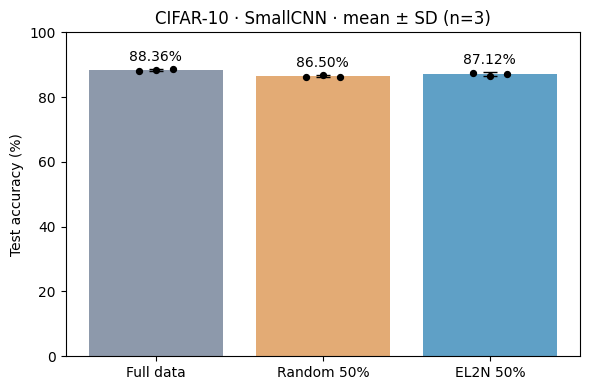

Test accuracy: среднее ± выборочное SD, %:
full: 88.36 ± 0.27
random: 86.50 ± 0.27
el2n: 87.12 ± 0.52

Разность точностей внутри повторов: среднее ± SD, п.п.:
el2n_minus_random_pp: +0.62 ± 0.78
el2n_minus_full_pp: -1.24 ± 0.52

Три повтора не доказывают статистическую значимость.
Отличия от статьи: небольшая CNN, одна модель EL2N в каждом повторе,
короткое обучение и другое расписание learning rate.
GraNd и Forget Score не воспроизводились.



In [8]:
order = ["full", "random", "el2n"]
assert not metrics.duplicated(["repeat", "method"]).any()
assert len(metrics) == 3 * len(CONFIG["seeds"])
aggregate = metrics.groupby("method").agg(
    runs=("test_accuracy_pct", "size"),
    accuracy_mean_pct=("test_accuracy_pct", "mean"),
    accuracy_std_pp=("test_accuracy_pct", "std"),
    train_minutes_mean=("train_minutes", "mean"),
    selection_minutes_mean=("selection_minutes", "mean"),
    total_minutes_mean=("train_plus_selection_minutes", "mean"),
).reindex(order)
aggregate.to_csv(RESULTS / "aggregate.csv")
display(aggregate.round(3))

paired = metrics.pivot(index="repeat", columns="method", values="test_accuracy_pct")
differences = pd.DataFrame({
    "el2n_minus_random_pp": paired["el2n"] - paired["random"],
    "el2n_minus_full_pp": paired["el2n"] - paired["full"],
})
differences.to_csv(RESULTS / "paired_differences.csv")
display(differences.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(3)
bars = ax.bar(
    x, aggregate["accuracy_mean_pct"], yerr=aggregate["accuracy_std_pp"],
    capsize=5, color=["#718096", "#dd9652", "#3789b8"], alpha=0.8,
)
ax.bar_label(bars, fmt="%.2f%%", padding=4)
offsets = np.linspace(-0.1, 0.1, len(CONFIG["seeds"]))
for position, name in enumerate(order):
    values = paired[name].to_numpy()
    ax.scatter(position + offsets, values, color="black", s=18, zorder=3)
kept_pct = 100 * CONFIG["keep_fraction"]
ax.set_xticks(x, ["Full data", f"Random {kept_pct:g}%", f"EL2N {kept_pct:g}%"])
ax.set(
    ylabel="Test accuracy (%)", ylim=(0, 100),
    title=f"CIFAR-10 · SmallCNN · mean ± SD (n={len(CONFIG['seeds'])})",
)
fig.tight_layout()
fig.savefig(RESULTS / "accuracy.png", dpi=160)
plt.show()

summary_lines = [
    "Test accuracy: среднее ± выборочное SD, %:",
    *[
        f"{name}: {row.accuracy_mean_pct:.2f} ± {row.accuracy_std_pp:.2f}"
        for name, row in aggregate.iterrows()
    ],
    "",
    "Разность точностей внутри повторов: среднее ± SD, п.п.:",
    *[
        f"{name}: {values.mean():+.2f} ± {values.std(ddof=1):.2f}"
        for name, values in differences.items()
    ],
    "",
    "Три повтора не доказывают статистическую значимость.",
    "Отличия от статьи: небольшая CNN, одна модель EL2N в каждом повторе,",
    "короткое обучение и другое расписание learning rate.",
    "GraNd и Forget Score не воспроизводились.",
]
summary = "\n".join(summary_lines) + "\n"
(RESULTS / "summary.txt").write_text(summary, encoding="utf-8")
print(summary)


## 8. Скачать результаты

Архив содержит настройки, версии библиотек, все 9 итоговых результатов,
сводную таблицу, парные разности, график, оценки EL2N и индексы подвыборок
для каждого повтора, историю обучения. Контрольные точки остаются на Drive.

Ноутбук с выводами скачайте отдельно: **Файл → Скачать → Скачать IPYNB**.



In [9]:
from google.colab import files

archive = shutil.make_archive(
    f"/content/data_diet_results_{RUN_ID}", "zip", root_dir=RESULTS
)
print("Результаты:", RESULTS)
print("Архив:", archive)

files.download(archive)


Результаты: /content/drive/MyDrive/hw2_data_diet/4ad4ed70df4f/results
Архив: /content/data_diet_results_4ad4ed70df4f.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>